# 06 · Revenue Prediction Modelling & Business Driver Analysis
**Customer Revenue Intelligence**, Step 8

> ⚠️ **SYNTHETIC DATA.** Input: `customer_sales_cleaned.csv` (Step 3). Step 5/6 labels are used only to group results. Customers are identified by `Customer_ID` only.

This notebook presents the pipeline in `src/prediction.py`.

**Prediction ≠ causation.** The model learns which historical characteristics are *associated* with next-quarter revenue. It does not show what would happen if a business lever were changed.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import joblib
from IPython.display import Image
import config
from src import prediction as pr

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 150)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FIG = config.FIGURES_DIR

# Full pipeline: panel -> leakage audit -> split -> feature selection -> baselines/models -> tuning -> test -> analysis -> save
R = pr.run_prediction(make_plots=True, verbose=False)
print(f"Panel rows: {len(R['panel']):,} | final model: {R['selection']['chosen']} | files: {len(R['saved'])} | figures: {len(R['figures'])}")

Panel rows: 10,393 | final model: Linear regression | files: 31 | figures: 10


## 1. Prediction Objective
Predict each existing customer's **Delivered revenue in the next quarter**, using only information available before the quarter starts. Then:
- measure the accuracy on quarters the model never saw;
- describe which customer, product, pricing, discount and regional characteristics the model associates with revenue.

## 2. Business Problem

In [2]:
pd.read_csv(config.TABLES_DIR / 'revenue_prediction_design.csv')

,Item,Definition
0,Prediction unit,Customer x quarter: each customer with >= 1 Delivered order in the 12 months before a quarter start
1,Target variable,Next_Quarter_Revenue: Delivered Sales (Rs) in the 3 months after the cutoff (0 if no purchase)
2,Feature period,12 months before each cutoff (3-month sub-window for recent activity)
3,Prediction period,the calendar quarter starting at the cutoff
4,Cutoffs,"2024-01-01, 2024-04-01, 2024-07-01, 2024-10-01, 2025-01-01, 2025-04-01, 2025-07-01, 2025-10-01"
5,Training period (targets),2024-01-01 to 2024-12-31
6,Validation period (targets),2025-01-01 to 2025-06-30
7,Test period (targets),2025-07-01 to 2025-12-31
8,Business purpose,Plan next-quarter revenue from the existing customer base and identify the measurable characteristics the model associates with it
9,Not covered,Revenue from customers with no order in the prior 12 months (new or reactivated)


**Why this prediction unit:**
- **Not individual transactions:** predicting a line's Sales from Quantity × Price is an identity, not a forecast.
- **Not category- or region-month aggregates:** that is time-series forecasting, which is Step 9.
- **Customer × quarter** matches how a business plans revenue from its existing base. It also allows customer, product and regional features, plus segment analysis.

## 3. Dataset Preparation

In [3]:
R['data']['checks']

,Check,Value,Pass
0,Order lines (cleaned),"18,670",True
1,Duplicate Order_Line_ID,0,True
2,"Missing values in key columns (date, customer, sales, status)",0,True
3,Date range,2023-01-01 to 2025-12-31,True
4,Step 5 RFM rows / duplicate Customer_ID,"1,984 / 0",True
5,Step 6 cluster rows / duplicate Customer_ID,"1,984 / 0",True
6,Step 7 value-history rows / duplicate Customer_ID,"1,984 / 0",True
7,Label merge one-to-one (validate='one_to_one'),"1,984 rows",True
8,Target period available for last test cutoff,2025-10-01 + 3 months <= 2025-12-31 + 1 day,True


In [4]:
R['timing']

,Cutoff,Max_Feature_Date,Min_Target_Date,Max_Target_Date,Customers,Quarter_Total_Revenue,Revenue_Covered,Coverage_%
0,2024-01-01,2023-12-31,2024-01-01,2024-03-31,1137,"4,504,728.450","3,689,011.750",81.892
1,2024-04-01,2024-03-31,2024-04-01,2024-06-30,1181,"3,936,445.200","3,295,315.600",83.713
2,2024-07-01,2024-06-30,2024-07-01,2024-09-30,1213,"4,366,677.200","3,750,295.700",85.884
3,2024-10-01,2024-09-30,2024-10-01,2024-12-31,1257,"6,961,904.050","6,073,076.450",87.233
4,2025-01-01,2024-12-31,2025-01-01,2025-03-31,1328,"5,698,626.300","4,905,711.300",86.086
5,2025-04-01,2025-03-31,2025-04-01,2025-06-30,1364,"6,482,765.800","5,883,242.850",90.752
6,2025-07-01,2025-06-30,2025-07-01,2025-09-30,1380,"6,965,585.750","6,090,234.200",87.433
7,2025-10-01,2025-09-30,2025-10-01,2025-12-31,1533,"8,078,959.150","6,802,324.700",84.198


- **Data checks:** no duplicate keys, no missing key values, and one-to-one label merges.
- **Panel:** each of the 8 quarterly cut-off dates includes every customer with at least one Delivered order in the previous 12 months. That population accounts for 82–91% of each quarter's revenue; the rest comes from new or reactivated customers, who are outside the panel.

## 4. Target Definition

In [5]:
p = R["panel"]
print("Target:", pr.TARGET, "= Delivered Sales in [cutoff, cutoff + 3 months)")
print(f"Rows: {len(p):,} | zero-revenue rows: {(p[pr.TARGET] == 0).mean():.1%} | mean: Rs {p[pr.TARGET].mean():,.0f} | "
      f"median: Rs {p[pr.TARGET].median():,.0f} | P99: Rs {p[pr.TARGET].quantile(.99):,.0f}")
p.groupby("Target_Period")[pr.TARGET].agg(["count", "mean", "sum", lambda s: (s == 0).mean()]).rename(columns={"<lambda_0>": "zero_share"})

Target: Next_Quarter_Revenue = Delivered Sales in [cutoff, cutoff + 3 months)
Rows: 10,393 | zero-revenue rows: 54.0% | mean: Rs 3,896 | median: Rs 0 | P99: Rs 51,118


,count,mean,sum,zero_share
Target_Period,,,,
2024-Q1,1137,"3,244.513","3,689,011.750",0.623
2024-Q2,1181,"2,790.276","3,295,315.600",0.634
2024-Q3,1213,"3,091.752","3,750,295.700",0.608
2024-Q4,1257,"4,831.405","6,073,076.450",0.448
2025-Q1,1328,"3,694.060","4,905,711.300",0.517
2025-Q2,1364,"4,313.228","5,883,242.850",0.457
2025-Q3,1380,"4,413.213","6,090,234.200",0.484
2025-Q4,1533,"4,437.263","6,802,324.700",0.571


About half of all customer-quarters have **zero** revenue, and the rest are heavily right-skewed. As a result:
- **Customer-level MAPE is undefined** and is not used.
- **What is reported instead:** MAE, RMSE, R², WAPE and the error on quarterly totals.

## 5. Feature Engineering

In [6]:
pd.read_csv(config.TABLES_DIR / 'revenue_feature_catalog.csv')

,Feature,Group,Type,Source_Window,Uses_Data_After_Cutoff,In_Final_Model
0,Recency_Days,Customer history,numeric,last Delivered order before cutoff,No,Yes
1,Rev_3M,Customer history,numeric,Sales in the 3 months before cutoff,No,Yes
2,Rev_12M,Customer history,numeric,Sales in the 12 months before cutoff,No,No (see feature selection)
3,Rev_Same_Quarter_Last_Year,Customer history,numeric,"Sales in [cutoff-12m, cutoff-9m)",No,Yes
4,Profit_12M,Customer history,numeric,"Profit, 12 months before cutoff",No,No (see feature selection)
5,Profit_Margin_12M,Customer history,numeric,Profit_12M / Rev_12M,No,Yes
6,Orders_3M,Customer history,numeric,"orders, 3 months before cutoff",No,Yes
7,Orders_12M,Customer history,numeric,"orders, 12 months before cutoff",No,Yes
8,Quantity_12M,Customer history,numeric,"units, 12 months before cutoff",No,No (see feature selection)
9,AOV_12M,Customer history,numeric,Rev_12M / Orders_12M,No,Yes


In [7]:
R['feature_selection']['table']

,Feature,Group,VIF_All_Candidates,Decision,Reason,Drop_Order,VIF_Final_Set,Spearman_with_Target_(train)
0,Recency_Days,Customer history,4.622,Kept,core measure (always kept),NaN,2.974,-0.198
1,Rev_3M,Customer history,10.596,Kept,VIF <= 10,NaN,9.263,0.195
2,Rev_12M,Customer history,"2,509.503",Excluded,exact identity = AOV_12M x Orders_12M,NaN,NaN,0.210
3,Rev_Same_Quarter_Last_Year,Customer history,1.862,Kept,VIF <= 10,NaN,1.814,0.077
4,Profit_12M,Customer history,1.646,Excluded,exact identity = AOV_12M x Orders_12M x Profit_Margin_12M,NaN,NaN,0.237
5,Profit_Margin_12M,Customer history,11.021,Kept,core measure (always kept),NaN,8.811,-0.043
6,Orders_3M,Customer history,10.540,Kept,VIF <= 10,NaN,9.965,0.186
7,Orders_12M,Customer history,586.064,Kept,core measure (always kept),NaN,4.840,0.233
8,Quantity_12M,Customer history,54.595,Excluded,VIF 53.9 > 10,4.000,NaN,0.228
9,AOV_12M,Customer history,"1,207.096",Kept,core measure (always kept),NaN,6.200,0.135


In [8]:
R['level_check']

,Specification,Distinct_Training_Values_of_Company_Level,Val_R2,Val_RMSE,Val_Total_Bias_%
0,Final feature set (shares / ratios),4,0.038,"9,436.425",-20.710
1,+ Company_Rev_3M and Region_Rev_3M (Rs levels),4,-0.112,"10,142.471",-95.370


- **What every feature uses:** only data dated before the cut-off.
- **Selection** (done on the training rows only):
  - exact products are removed (Rev_12M = AOV × Orders; Profit_12M = AOV × Orders × margin);
  - then the non-core feature with the highest VIF above 10 is dropped, repeatedly.
- **What that removed:**
  - one category share (the shares sum to 1);
  - company trend (the same as the quarter indicator in training);
  - both regional share features, which nearly duplicate Region;
  - Quantity;
  - the point-in-time RFM score, which is built from recency, orders and revenue.
- **Design iteration:**
  - The first specification used company and regional revenue *levels* in ₹, but these take only 4 distinct values in training and act as a time trend.
  - With them, Linear Regression's validation total bias was −95%.
  - They were replaced by scale-free shares and ratios. The report documents this iteration openly.
- **Encoding:**
  - numeric features: median imputation, then arcsinh for skewed features, then standardisation;
  - categorical features: one-hot encoding;
  - everything sits inside one pipeline, fitted on training rows only.

## 6. Temporal Split

In [9]:
R['split']['summary']

,Split,Cutoffs,Feature_Data_From,Feature_Data_To,Target_Period,Target_Quarters,Rows,Customers,Zero_Target_%,Mean_Target,Total_Target
0,train,"2024-01-01, 2024-04-01, 2024-07-01, 2024-10-01",2023-01-01,2024-09-30,2024-01-01 to 2024-12-31,"2024-Q1, 2024-Q2, 2024-Q3, 2024-Q4",4788,1487,57.602,"3,510.380","16,807,699.500"
1,validation,"2025-01-01, 2025-04-01",2024-01-01,2025-03-31,2025-01-01 to 2025-06-30,"2025-Q1, 2025-Q2",2692,1441,48.663,"4,007.784","10,788,954.150"
2,test,"2025-07-01, 2025-10-01",2024-07-01,2025-09-30,2025-07-01 to 2025-12-31,"2025-Q3, 2025-Q4",2913,1560,52.969,"4,425.870","12,892,558.900"


In [10]:
R['leakage']['excluded']

,Variable,Why it is available,Decision / reason
0,Next_Quarter_Revenue / Next_Quarter_Orders,Target-period values,Future information - target only
1,Future Sales / Profit / Quantity / Discount / activity,Any line dated >= cutoff,Would reveal the answer; all feature windows end the day before the cutoff
2,"RFM_Segment, R/F/M scores (Step 5)",Computed on 2023-2025 incl. target quarters,Look-ahead; replaced by RFM_Score_at_Cutoff; used only to group errors
3,Cluster_ID (Step 6),K-Means fitted on 2023-2025 incl. target quarters,Look-ahead; used only to group errors
4,Historical_Profit_CLV / Estimated CLV (Step 7),Full-period totals and a model fitted on 2024-2025 targets,Look-ahead
5,Sales = Quantity x Unit_Price x (1 - Discount) of the same order,Same-period identity,"Trivial, not a planning problem"
6,"Customer_Name, Customer_ID",Identifiers,No predictive meaning; privacy
7,"Gender, Customer_Age, City, State",Demographics / high-cardinality location,Not needed for planning; Region carries location; avoids demographic profiling


In [11]:
R['leakage']['checks']

,Check,Pass
0,Max feature date < cutoff at every cutoff,True
1,Min target date >= cutoff at every cutoff,True
2,Target window <= 3 months after cutoff,True
3,No target / future / full-period label column among model features,True
4,Correlation check: no feature has |Spearman| > 0.95 with the target (training rows),True


- **Split, in time order:**

| Split | Target quarters |
|---|---|
| Train | 2024 Q1–Q4 |
| Validation | 2025 Q1–Q2 |
| Test | 2025 Q3–Q4 |

- **Leakage audit:** every feature window ends the day before its cut-off date.
- **Kept out of the features:** Step 5 RFM segments, Step 6 clusters and Step 7 CLV values, because they were computed on the full period.

## 7. Baseline Model

In [12]:
R['evaluation']['results'][R['evaluation']['results']['Type'] == 'Baseline']

,Model,Type,Stage,Train_MAE,Train_RMSE,Train_R2,Train_WAPE_%,Train_Spearman,Train_Total_Bias_%,Val_MAE,Val_RMSE,Val_R2,Val_WAPE_%,Val_Spearman,Val_Total_Bias_%,Overfit_Gap_R2
0,Baseline: previous quarter (naive),Baseline,default,"5,376.798","13,166.421",-0.810,153.169,0.195,5.014,"5,904.247","12,815.768",-0.775,147.319,0.232,17.347,-0.034
1,Baseline: same quarter last year (seasonal naive),Baseline,default,"4,945.527","12,149.479",-0.541,140.883,0.077,-22.292,"5,587.549","12,883.604",-0.794,139.417,0.078,-21.761,0.253
2,Baseline: 12-month quarterly mean,Baseline,default,"4,575.194","10,145.418",-0.075,130.333,0.210,-6.711,"4,914.701","10,161.293",-0.116,122.629,0.260,-5.613,0.041


Three baselines with no fitting:
- **Previous quarter's revenue.**
- **Same quarter last year.**
- **The 12-month quarterly mean.** This is the strongest of the three: on validation, MAE ₹4,915 and R² −0.12.

## 8. Model Training

In [13]:
print("Numeric features:", len(pr.NUMERIC_FEATURES), "| categorical:", pr.CATEGORICAL_FEATURES)
m = R["evaluation"]["models"]["Linear regression"]
m

Numeric features: 19 | categorical: ['Region', 'Main_Category', 'Main_Payment_Method', 'Acquisition_Status', 'Target_Quarter']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('skewed', ...), ('numeric', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different trans

## 9. Model Comparison

In [14]:
R['evaluation']['results'][['Model', 'Type', 'Train_R2', 'Val_MAE', 'Val_RMSE', 'Val_R2', 'Val_WAPE_%', 'Val_Total_Bias_%', 'Overfit_Gap_R2']]

,Model,Type,Train_R2,Val_MAE,Val_RMSE,Val_R2,Val_WAPE_%,Val_Total_Bias_%,Overfit_Gap_R2
0,Baseline: previous quarter (naive),Baseline,-0.810,"5,904.247","12,815.768",-0.775,147.319,17.347,-0.034
1,Baseline: same quarter last year (seasonal naive),Baseline,-0.541,"5,587.549","12,883.604",-0.794,139.417,-21.761,0.253
2,Baseline: 12-month quarterly mean,Baseline,-0.075,"4,914.701","10,161.293",-0.116,122.629,-5.613,0.041
3,Linear regression,ML model,0.059,"4,522.796","9,436.425",0.038,112.850,-20.710,0.022
4,Random forest,ML model,0.437,"5,003.159","9,466.089",0.031,124.836,11.213,0.406
5,Gradient boosting,ML model,0.472,"5,037.476","9,753.356",-0.028,125.692,6.910,0.500


- **Overfitting:** the tree models fit the training data far better than validation (R² gaps of about 0.4–0.5). Linear Regression has almost no gap.
- **Linear Regression on validation:** it beats all baselines on RMSE and MAE.

## 10. Hyperparameter Tuning

In [15]:
print(R['tuning']['candidate'], '| best params:', R['tuning']['best_params'])
R['tuning']['results'].head(10)

Random forest | best params: {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 20, 'max_features': 0.3, 'max_depth': None}


,Iteration,n_estimators,min_samples_split,min_samples_leaf,max_features,max_depth,Val_MAE,Val_RMSE,Val_R2,Val_WAPE_%,Val_Spearman,Val_Total_Bias_%,Train_R2
0,13,100,10,20,0.3,None,"4,745.184","9,340.020",0.057,118.399,0.284,2.018,0.190
1,4,100,2,5,0.3,6,"4,781.967","9,356.593",0.054,119.317,0.273,2.805,0.218
2,10,100,10,10,0.3,10,"4,808.469","9,363.859",0.052,119.978,0.269,3.934,0.256
3,12,200,20,20,0.5,10,"4,785.347","9,365.157",0.052,119.401,0.274,3.537,0.196
4,15,200,20,5,0.5,10,"4,908.534","9,426.026",0.040,122.475,0.264,8.117,0.314
5,9,200,10,5,0.8,6,"4,833.049","9,439.386",0.037,120.592,0.270,3.632,0.258
6,2,300,2,5,0.8,6,"4,824.731","9,441.046",0.037,120.384,0.272,3.374,0.256
7,1,200,20,5,1.0,6,"4,851.091","9,445.268",0.036,121.042,0.270,4.453,0.229
8,6,300,2,5,0.5,None,"5,003.159","9,466.089",0.031,124.836,0.258,11.213,0.437
9,11,200,10,10,1.0,16,"4,956.296","9,475.562",0.030,123.667,0.257,8.643,0.314


In [16]:
R['selection']['table']

,Model,Val_RMSE,Val_MAE,Val_R2,Train_R2,Overfit_Gap_R2,Complexity_Rank,Within_2%_of_Best,Selected
0,Linear regression,"9,436.425","4,522.796",0.038,0.059,0.022,0,True,True
1,Random forest,"9,466.089","5,003.159",0.031,0.437,0.406,1,True,False
2,Gradient boosting,"9,753.356","5,037.476",-0.028,0.472,0.500,2,False,False
3,Random forest (tuned),"9,340.020","4,745.184",0.057,0.190,0.132,1,True,False


- **What was tuned:** the stronger tree model (Random Forest), with 15 random settings. Each was fitted on train and scored on validation.
- **Tuning result:** best validation RMSE ₹9,340 vs ₹9,466 for the default, with a much smaller overfitting gap.
- **Selection rule (fixed in advance):** keep models within 2% of the best validation RMSE, then choose the simplest model type.
- **Outcome:** Linear Regression (₹9,436, within 1.0%) is selected.

## 11. Model Evaluation

In [17]:
R['test_results']

,Model,Type,MAE,RMSE,R2,WAPE_%,Spearman,Total_Bias_%,Selected
0,Baseline: previous quarter (naive),Baseline,"6,422.694","14,483.336",-0.570,145.117,0.129,4.311,False
1,Baseline: same quarter last year (seasonal naive),Baseline,"5,880.344","13,557.152",-0.376,132.863,0.158,-12.131,False
2,Baseline: 12-month quarterly mean,Baseline,"5,436.149","11,466.315",0.016,122.827,0.224,-3.784,False
3,Linear regression,ML model,"5,657.567","11,232.420",0.056,127.829,0.175,1.122,True
4,Random forest,ML model,"5,762.310","11,264.975",0.050,130.196,0.171,8.012,False
5,Gradient boosting,ML model,"5,845.292","11,382.926",0.030,132.071,0.158,10.149,False
6,Random forest (tuned),ML model,"5,553.976","11,148.400",0.070,125.489,0.201,2.303,False


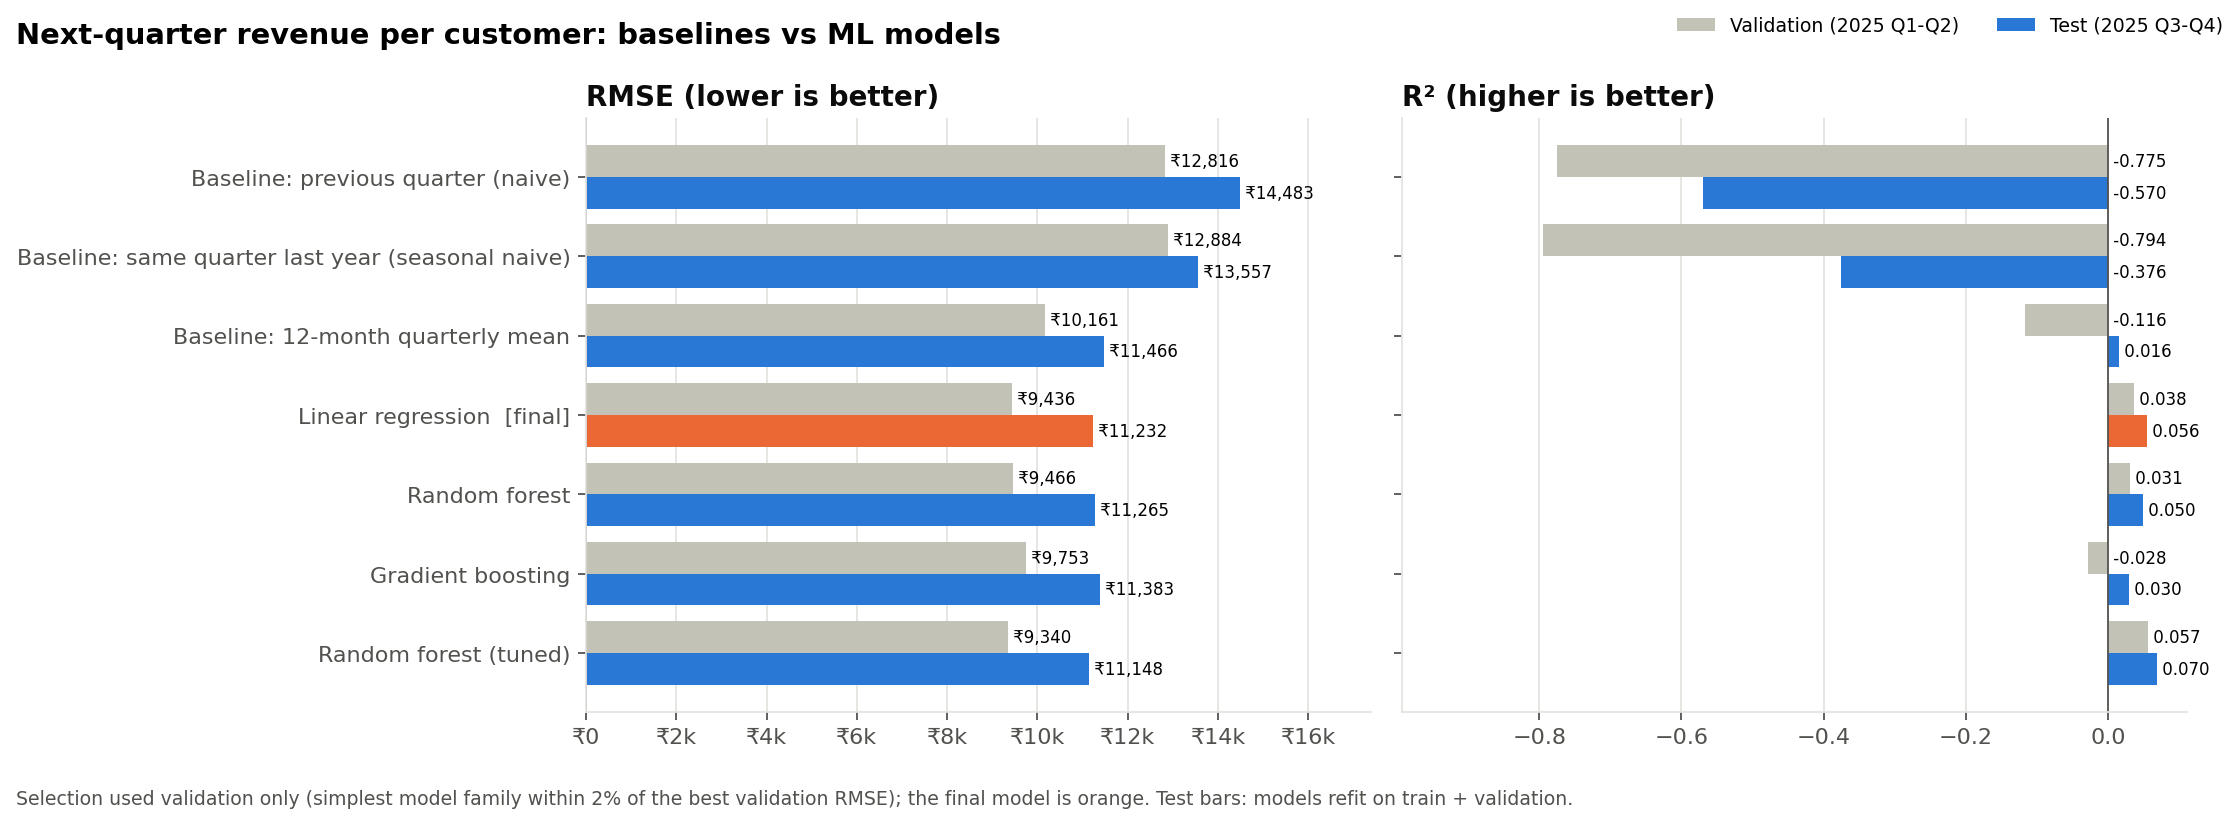

In [18]:
Image(str(FIG / "revenue_model_comparison.png"))

In [19]:
R['timeline']

,Target_Period,Split,Actual_Revenue,Predicted_Revenue,Naive_Baseline,Customers,Error_%,Naive_Error_%
0,2024-Q1,train (in-sample fit),"3,689,011.750","3,689,011.750","4,842,555.250",1137,-0.000,31.270
1,2024-Q2,train (in-sample fit),"3,295,315.600","3,295,315.600","4,504,728.450",1181,-0.000,36.701
2,2024-Q3,train (in-sample fit),"3,750,295.700","3,750,295.700","3,936,445.200",1213,-0.000,4.964
3,2024-Q4,train (in-sample fit),"6,073,076.450","6,073,076.450","4,366,677.200",1257,-0.000,-28.098
4,2025-Q1,validation (out-of-sample),"4,905,711.300","4,637,720.241","6,961,904.050",1328,-5.463,41.914
5,2025-Q2,validation (out-of-sample),"5,883,242.850","3,916,809.534","5,698,626.300",1364,-33.424,-3.138
6,2025-Q3,test (out-of-sample),"6,090,234.200","4,937,971.832","6,482,765.800",1380,-18.920,6.445
7,2025-Q4,test (out-of-sample),"6,802,324.700","8,099,266.577","6,965,585.750",1533,19.066,2.400


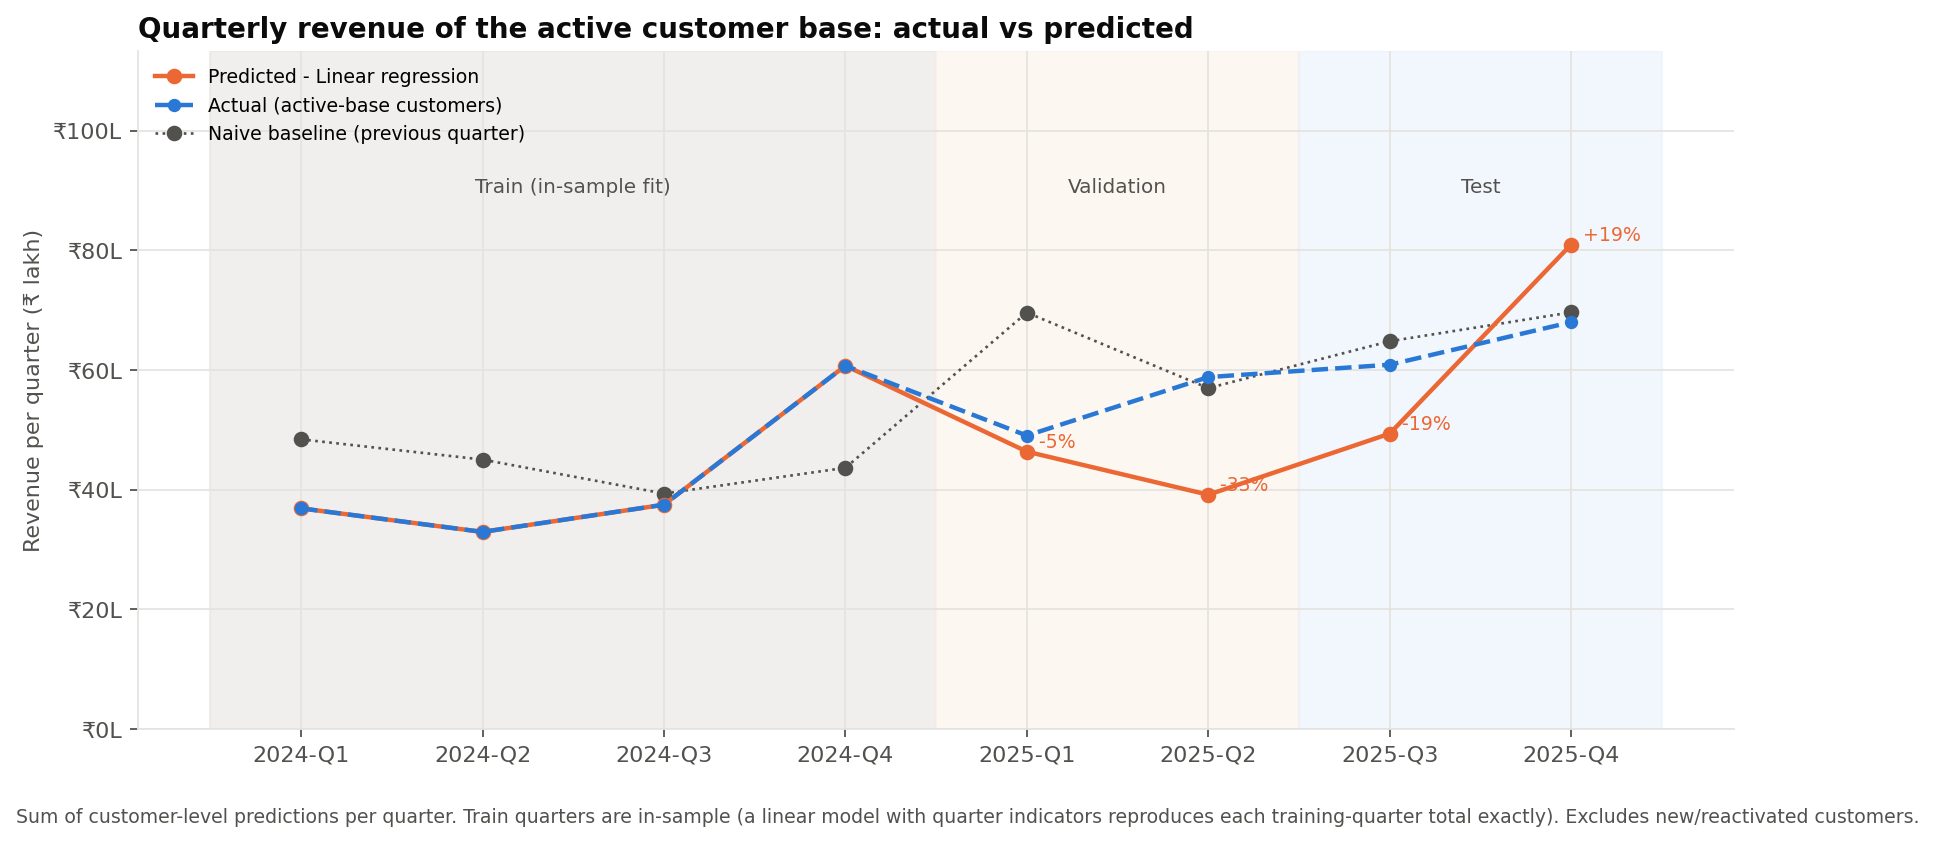

In [20]:
Image(str(FIG / "revenue_prediction_timeline.png"))

**Test results for the final Linear Regression (2025 Q3–Q4, 2,913 customer-quarters; not used for model selection or tuning):**
- MAE ₹5,658, RMSE ₹11,232, R² 0.056, total bias +1.1%.

**Against the 12-month-mean baseline:**
- RMSE and R² are better (₹11,466 and 0.016 for the baseline).
- MAE is worse (₹5,436 for the baseline).
- The tuned Random Forest had the best test figures (R² 0.070), but it was not chosen, because the test set was not used for selection.

**Quarterly totals:**
- The model missed by −18.9% (Q3) and +19.1% (Q4), against +6.4% and +2.4% for the naive rule.
- The quarter effect was learned from a single year and did not carry over.

**Conclusion:** individual customers' next-quarter revenue is only weakly predictable from their history in this data.

## 12. Feature Importance

In [21]:
R['importance']

,Feature,Group,Permutation_MAE_Increase,Permutation_Std,Impurity_Importance,Rank
0,Orders_12M,Customer history,236.447,17.238,NaN,1
1,Main_Category,Product,41.431,7.171,NaN,2
2,Share_Books,Product,40.748,8.526,NaN,3
3,AOV_12M,Customer history,18.956,2.965,NaN,4
4,Categories_12M,Product,12.568,3.632,NaN,5
5,Acquisition_Status,Customer history,8.821,3.199,NaN,6
6,Profit_Margin_12M,Customer history,5.619,2.758,NaN,7
7,Share_Home_Kitchen,Product,5.428,1.945,NaN,8
8,Share_Sports,Product,4.940,1.614,NaN,9
9,Avg_Discount_12M,Customer history,4.486,1.963,NaN,10


In [22]:
R['coefficients'].head(15)

,Encoded_Feature,Coefficient,Raw_Feature,Transform
0,Main_Category_Books,"2,533.469",Main_Category,one-hot
1,Orders_12M,"1,615.504",Orders_12M,arcsinh + standardise
2,Target_Quarter_Q4,"1,177.761",Target_Quarter,one-hot
3,Main_Category_Home & Kitchen,"-1,077.089",Main_Category,one-hot
4,Main_Category_Fashion,-854.236,Main_Category,one-hot
5,Main_Payment_Method_Unknown,-789.845,Main_Payment_Method,one-hot
6,Target_Quarter_Q3,-620.065,Target_Quarter,one-hot
7,Share_Books,-579.708,Share_Books,standardise
8,Tenure_Days_Capped,-459.682,Tenure_Days_Capped,standardise
9,Categories_12M,408.241,Categories_12M,standardise


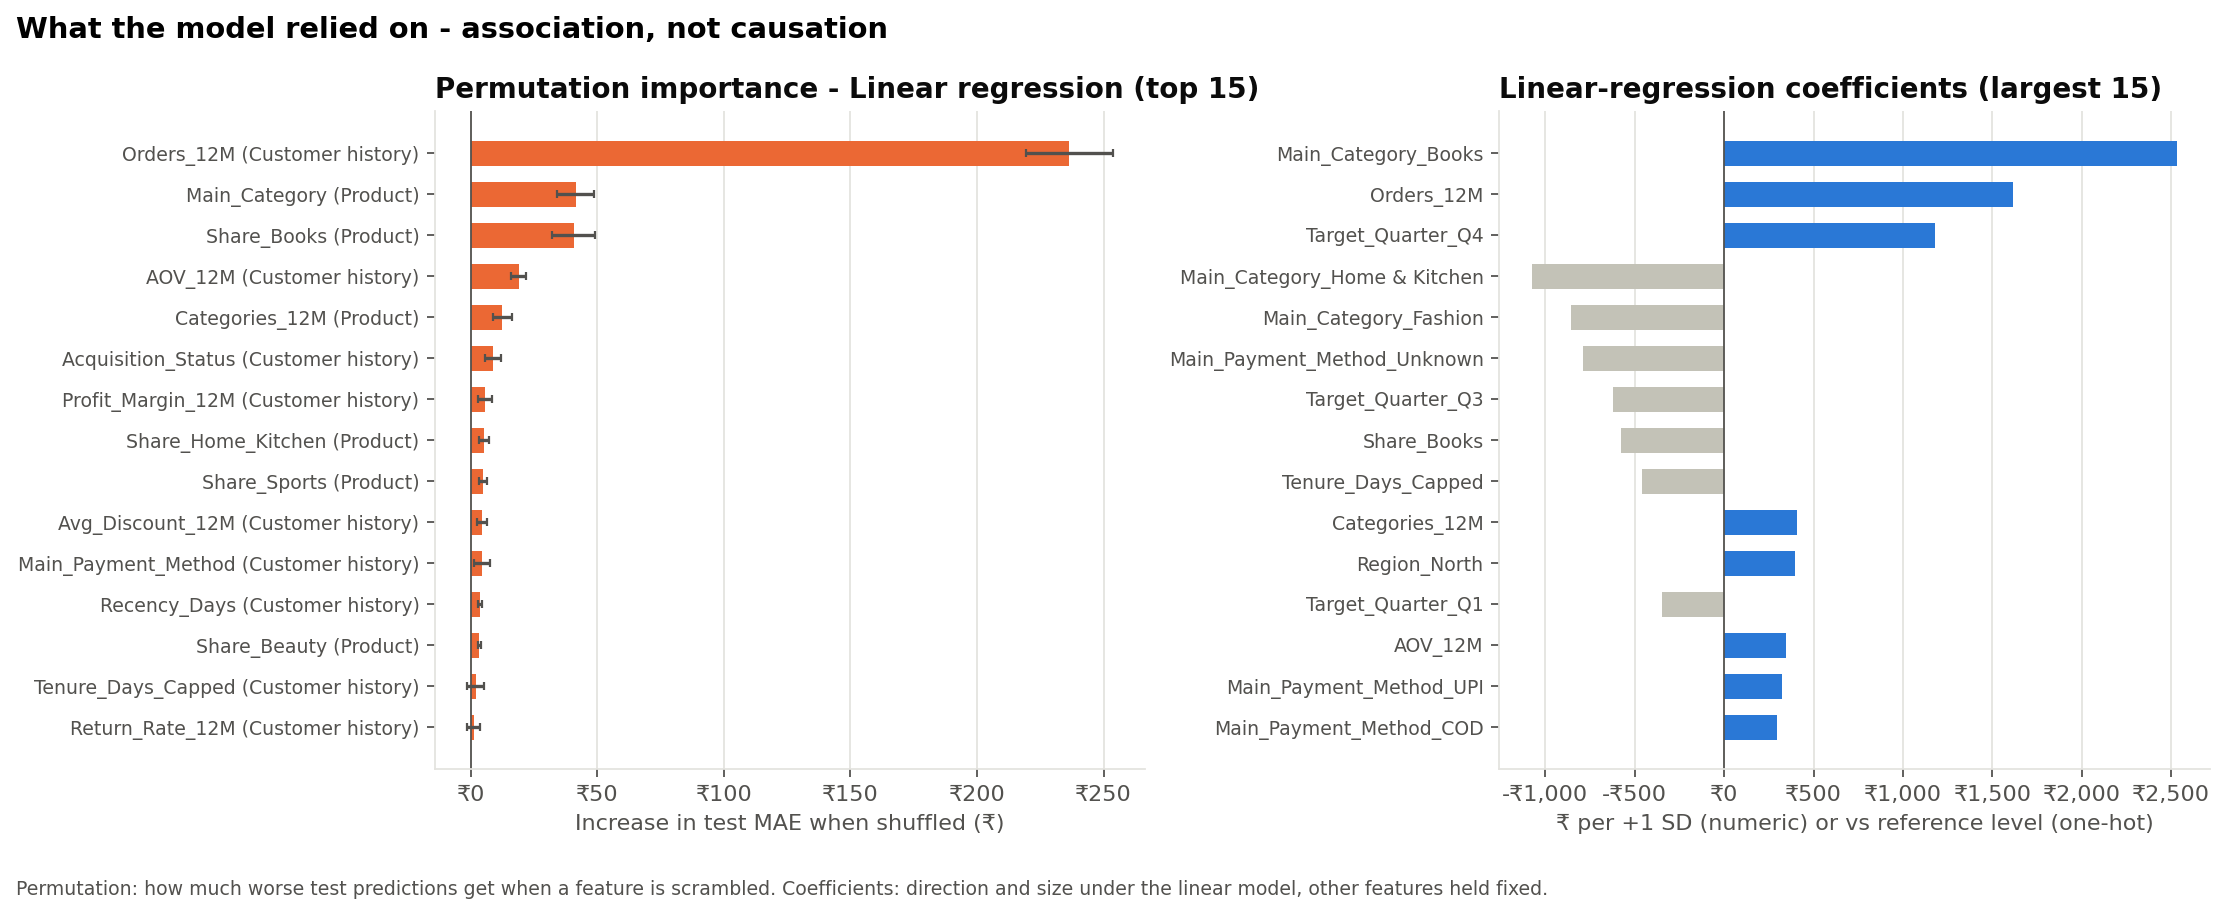

In [23]:
Image(str(FIG / "revenue_feature_importance.png"))

- **Past-12-month order count** is by far the most-used feature. Next come main category, category mix, AOV and number of categories.
- **Region, unit price, trend features and target quarter** add little or nothing on the test quarters.
- **How to read this:** *the model relied more heavily on these features*. It does **not** mean they cause revenue.

## 13. Prediction Analysis

In [24]:
preds = pd.read_csv(config.TABLES_DIR / "revenue_predictions.csv")
preds[["Customer_ID", "Target_Period", "Actual_Revenue", "Predicted_Revenue", "Prediction_Error", "Absolute_Error", "Percentage_Error_%"]].head(10)

,Customer_ID,Target_Period,Actual_Revenue,Predicted_Revenue,Prediction_Error,Absolute_Error,Percentage_Error_%
0,CUST-0001,2025-Q3,0.000,759.384,759.384,759.384,NaN
1,CUST-0002,2025-Q3,"1,782.400","4,146.782","2,364.382","2,364.382",132.652
2,CUST-0003,2025-Q3,"3,148.800","2,236.675",-912.125,912.125,-28.967
3,CUST-0005,2025-Q3,0.000,"7,193.461","7,193.461","7,193.461",NaN
4,CUST-0006,2025-Q3,"21,418.200","5,794.441","-15,623.759","15,623.759",-72.946
5,CUST-0007,2025-Q3,0.000,"2,788.632","2,788.632","2,788.632",NaN
6,CUST-0008,2025-Q3,"2,264.000","7,115.158","4,851.158","4,851.158",214.274
7,CUST-0010,2025-Q3,"2,515.500","3,167.110",651.610,651.610,25.904
8,CUST-0011,2025-Q3,0.000,"2,814.594","2,814.594","2,814.594",NaN
9,CUST-0012,2025-Q3,"5,292.800","1,665.436","-3,627.364","3,627.364",-68.534


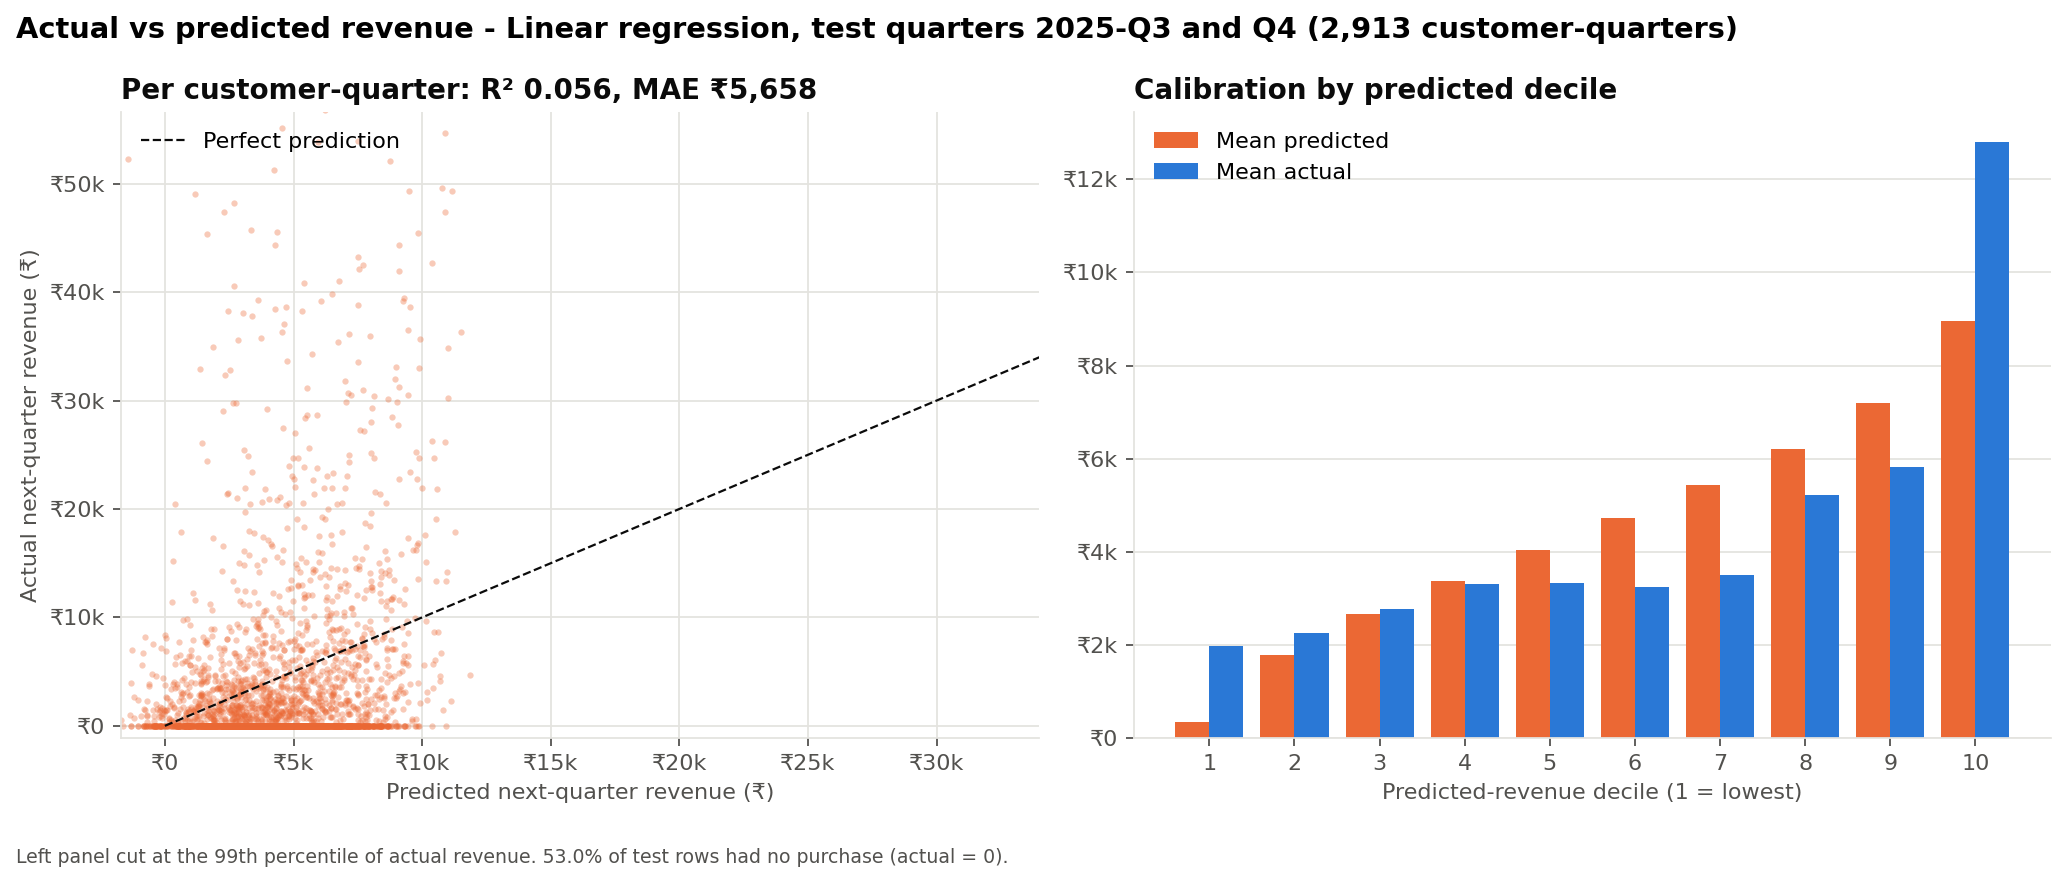

In [25]:
Image(str(FIG / "actual_vs_predicted_revenue.png"))

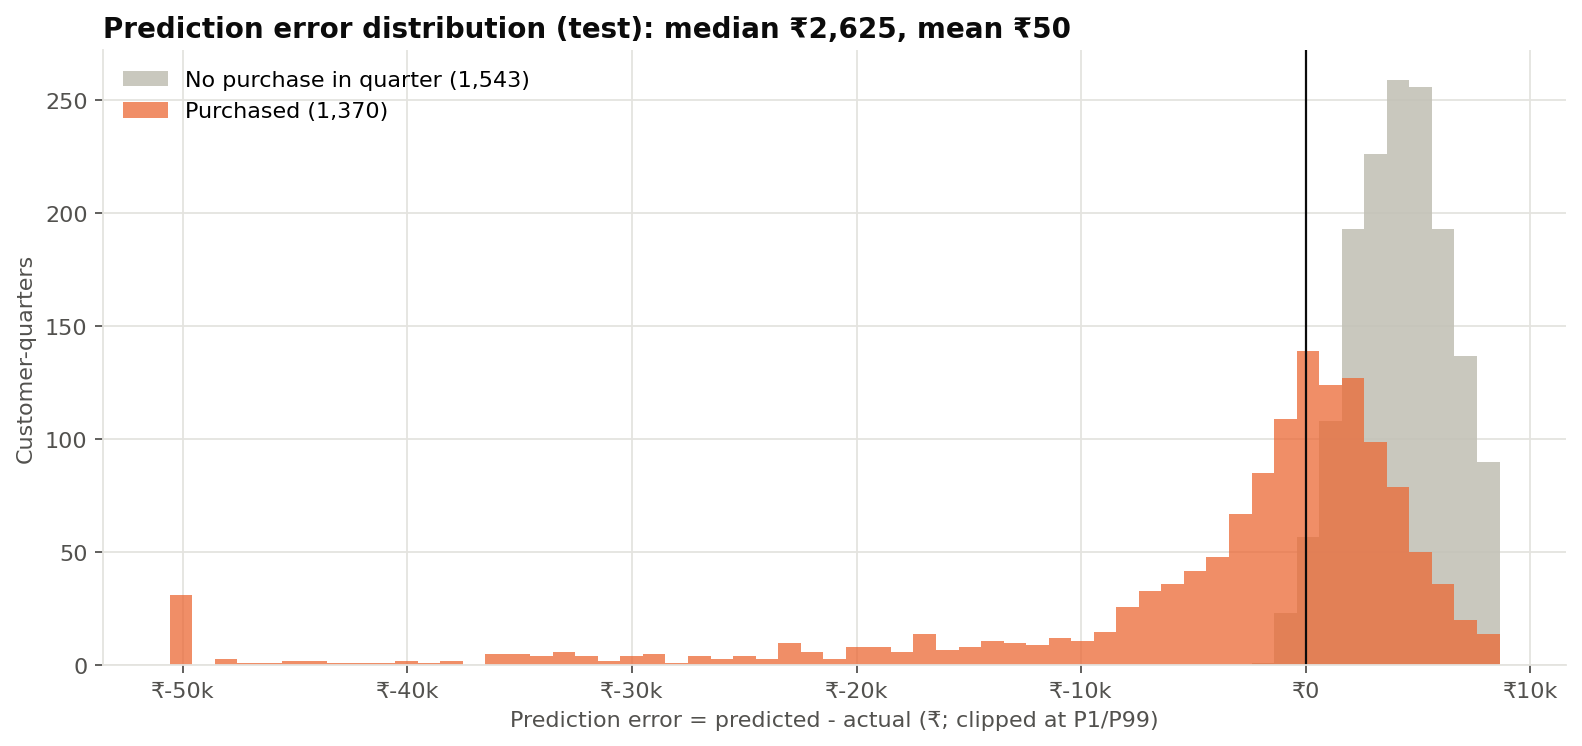

In [26]:
Image(str(FIG / "prediction_error_distribution.png"))

In [27]:
R['segments']['cluster']

,Cluster,Rows,Actual_Revenue,Predicted_Revenue,MAE,Median_Abs_Error,WAPE_%,Bias_%,Avg_Actual,Avg_Predicted,Predicted_Share_%,Actual_Share_%
0,"C0: High-Value, Active",719,"9,382,025.450","4,665,299.797","10,498.827","4,901.667",80.459,-50.274,"13,048.714","6,488.595",35.784,72.771
1,"C1: Low-Value, Active",461,"711,857.850","1,221,856.386","2,482.828","2,067.865",160.788,71.643,"1,544.160","2,650.448",9.372,5.521
2,"C2: Mid-Value, Lapsing",1418,"2,752,546.000","6,312,211.852","4,872.935","4,432.608",251.034,129.323,"1,941.147","4,451.489",48.417,21.350
3,"C3: Low-Value, Inactive",315,"46,129.600","837,870.374","2,785.494","2,687.470","1,902.099","1,716.340",146.443,"2,659.906",6.427,0.358


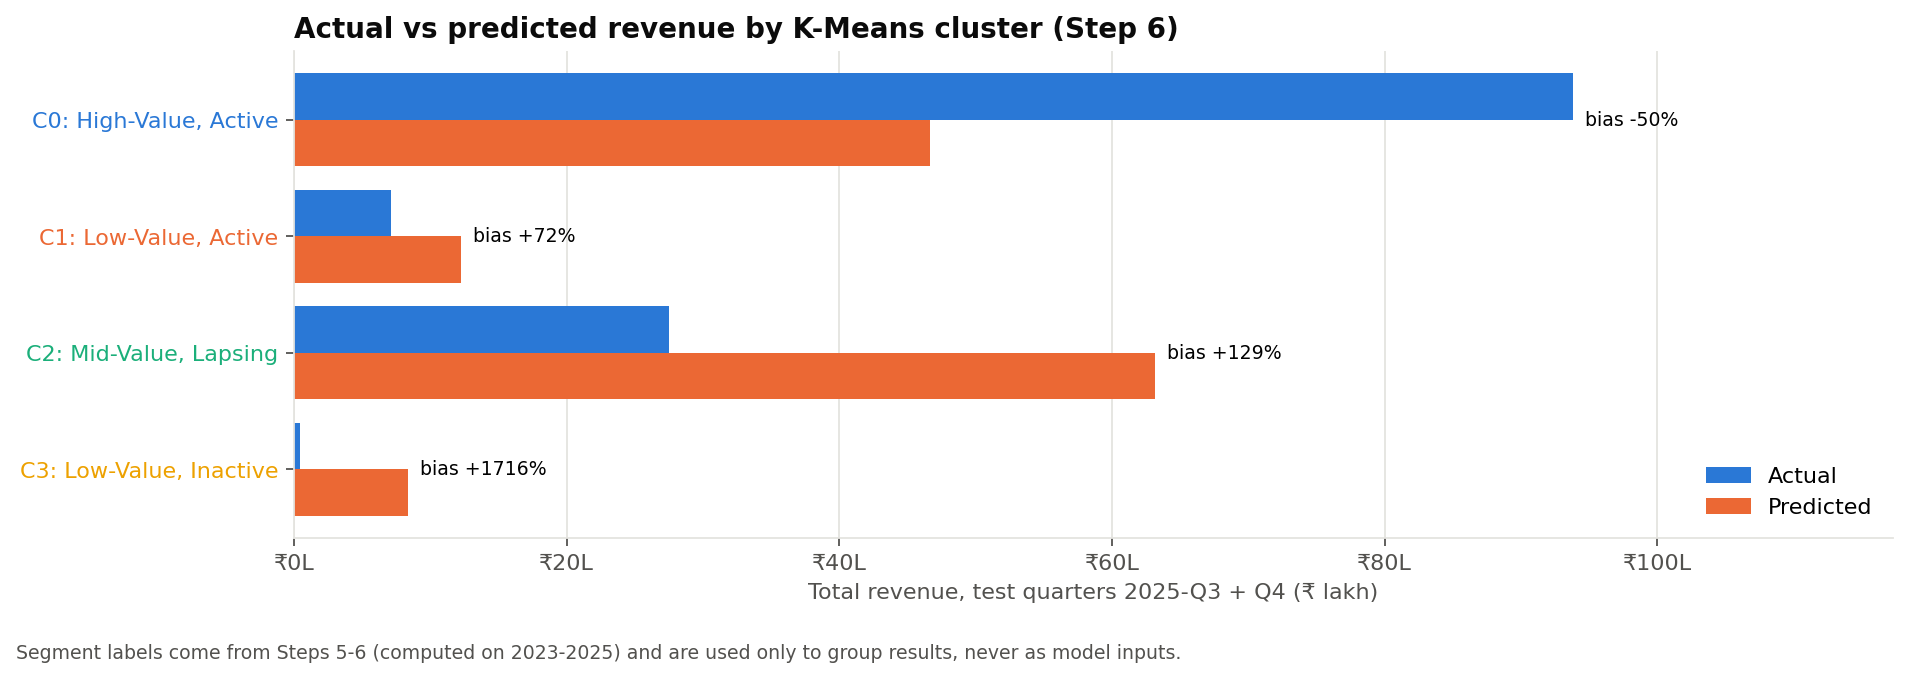

In [28]:
Image(str(FIG / "predicted_revenue_by_cluster.png"))

In [29]:
R['segments']['rfm']

,RFM_Segment,Rows,Actual_Revenue,Predicted_Revenue,MAE,Median_Abs_Error,WAPE_%,Bias_%,Avg_Actual,Avg_Predicted,Predicted_Share_%,Actual_Share_%
0,Champions,664,"9,140,817.750","4,402,422.661","10,985.583","5,013.162",79.801,-51.838,"13,766.292","6,630.155",33.768,70.900
1,Loyal Customers,449,"1,910,458.550","2,097,599.392","5,436.230","4,273.473",127.763,9.796,"4,254.919","4,671.714",16.089,14.818
2,Potential Loyalists,226,"661,466.250","614,122.732","2,947.916","2,007.913",100.720,-7.157,"2,926.842","2,717.357",4.711,5.131
3,Recent Customers,47,"69,639.300","114,711.264","1,753.477","1,386.364",118.343,64.722,"1,481.687","2,440.665",0.880,0.540
4,Promising,69,"136,397.800","149,847.058","1,551.866","1,246.669",78.505,9.860,"1,976.780","2,171.696",1.149,1.058
5,Needs Attention,221,"379,278.100","793,806.109","3,775.316","3,375.869",219.982,109.294,"1,716.190","3,591.883",6.089,2.942
6,About to Sleep,170,"111,360.600","497,543.800","3,171.023","3,053.080",484.080,346.786,655.062,"2,926.728",3.816,0.864
7,Can't Lose Them,157,"126,706.250","924,115.823","6,196.902","6,096.744",767.850,629.337,807.046,"5,886.088",7.088,0.983
8,At Risk,489,"267,756.100","2,285,912.663","4,769.878","4,705.032",871.118,753.729,547.558,"4,674.668",17.534,2.077
9,Hibernating,275,"88,678.200","832,745.968","3,155.448","3,163.297",978.536,839.065,322.466,"3,028.167",6.387,0.688


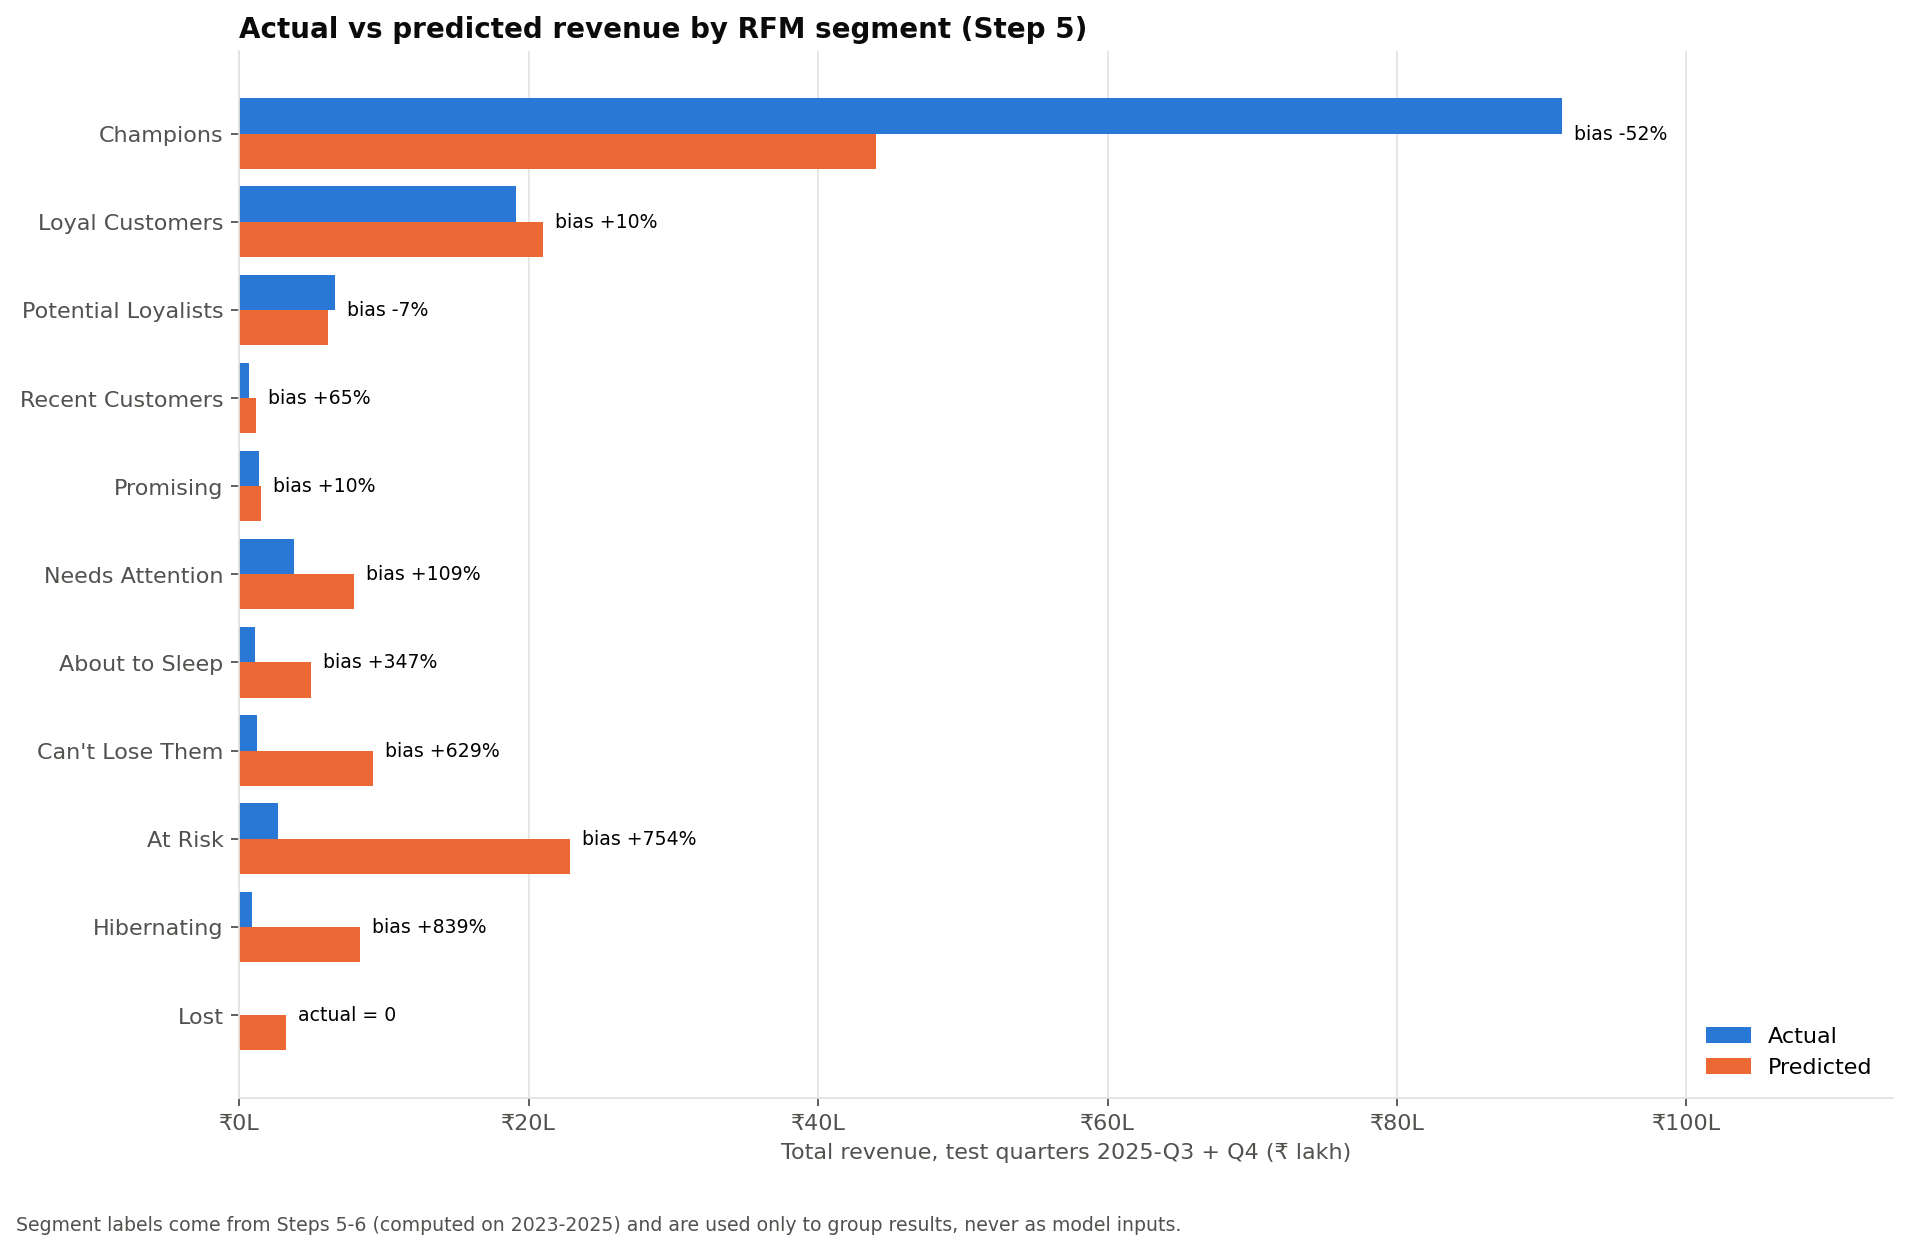

In [30]:
Image(str(FIG / "predicted_revenue_by_rfm.png"))

## 14. Error Analysis

In [31]:
R['errors']['quarter']

,Target_Period,Rows,Actual_Revenue,Predicted_Revenue,MAE,Median_Abs_Error,WAPE_%,Bias_%,Avg_Actual,Avg_Predicted
0,2025-Q3,1380,"6,090,234.200","4,937,971.832","5,137.321","3,030.764",116.408,-18.920,"4,413.213","3,578.240"
1,2025-Q4,1533,"6,802,324.700","8,099,266.577","6,125.890","4,460.584",138.056,19.066,"4,437.263","5,283.279"


In [32]:
R['errors']['region']

,Region,Rows,Actual_Revenue,Predicted_Revenue,MAE,Median_Abs_Error,WAPE_%,Bias_%,Avg_Actual,Avg_Predicted
0,Central,371,"1,548,391.250","1,552,311.371","5,315.591","3,650.886",127.363,0.253,"4,173.561","4,184.128"
1,East,383,"1,807,503.150","1,581,844.923","5,783.561","3,691.962",122.550,-12.485,"4,719.329","4,130.143"
2,North,652,"2,897,102.600","3,259,657.423","6,039.846","4,426.482",135.928,12.514,"4,443.409","4,999.475"
3,South,784,"3,533,769.700","3,462,933.062","5,629.189","3,634.685",124.889,-2.005,"4,507.359","4,417.006"
4,West,723,"3,105,792.200","3,180,491.629","5,452.338","3,702.089",126.925,2.405,"4,295.702","4,399.020"


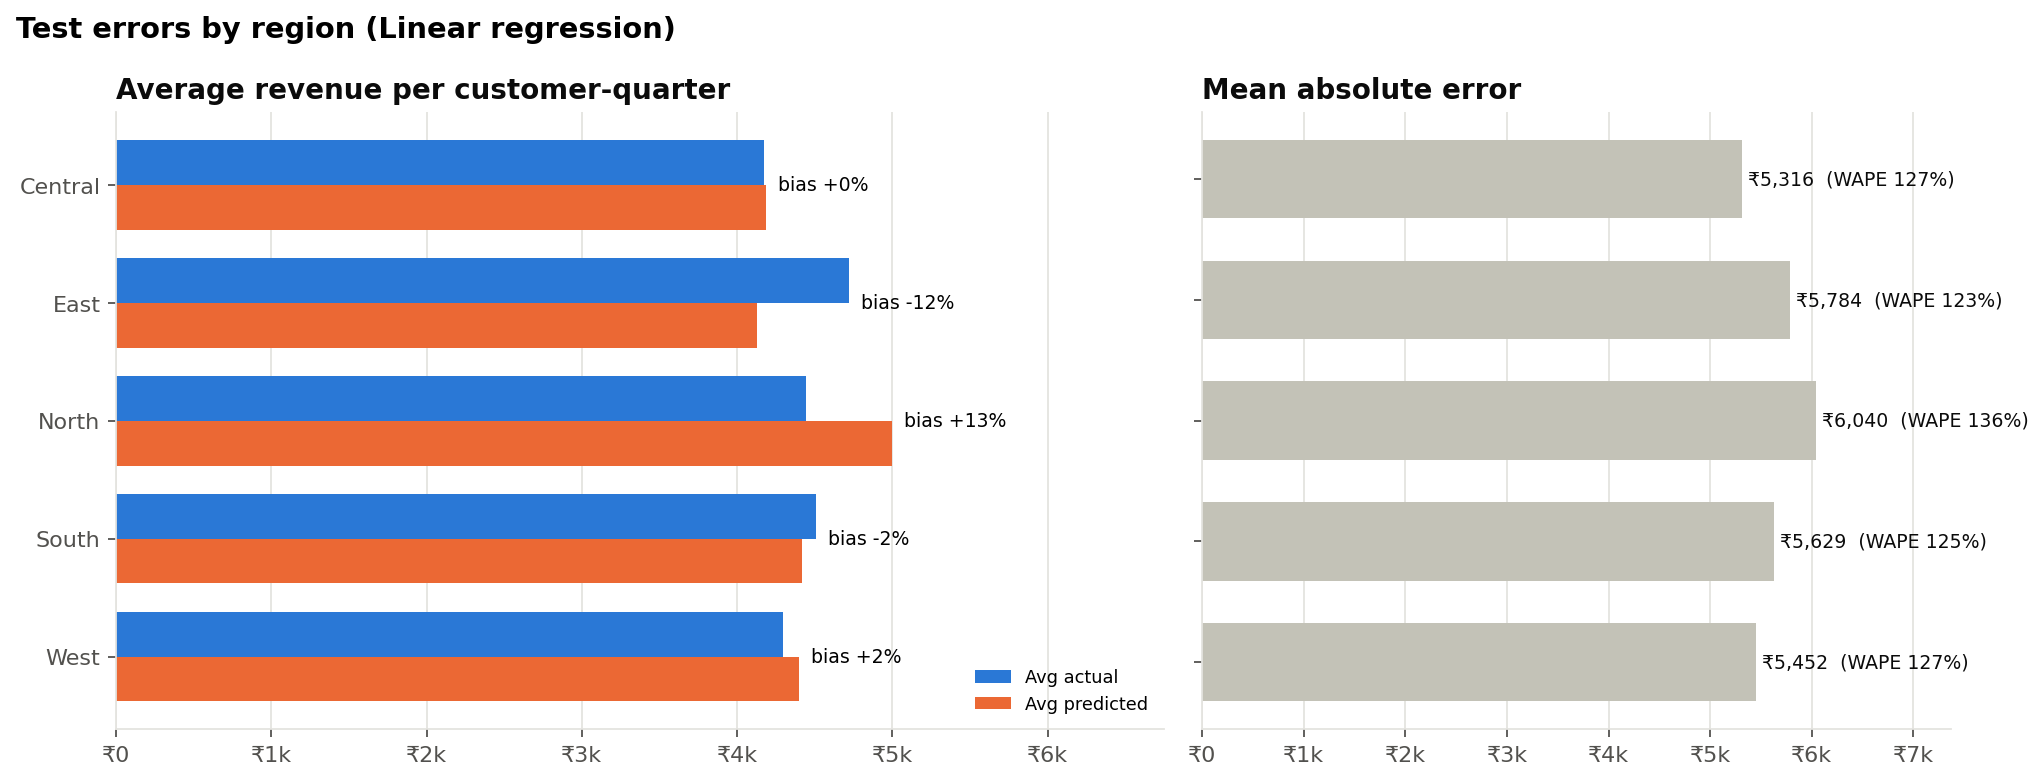

In [33]:
Image(str(FIG / "prediction_error_by_region.png"))

In [34]:
R['errors']['category']

,Main_Category,Rows,Actual_Revenue,Predicted_Revenue,MAE,Median_Abs_Error,WAPE_%,Bias_%,Avg_Actual,Avg_Predicted
0,Beauty,261,"693,479.100","844,124.160","4,083.343","2,731.776",153.682,21.723,"2,657.008","3,234.192"
1,Books,73,"129,332.550","211,673.996","3,523.509","2,994.804",198.880,63.666,"1,771.679","2,899.644"
2,Electronics,935,"5,640,312.600","5,496,555.203","7,097.872","4,967.508",117.662,-2.549,"6,032.420","5,878.669"
3,Fashion,947,"3,693,832.100","3,508,538.622","5,204.572","3,311.574",133.431,-5.016,"3,900.562","3,704.898"
4,Home & Kitchen,587,"2,414,432.400","2,541,218.327","5,283.735","3,765.699",128.459,5.251,"4,113.173","4,329.162"
5,Sports,110,"321,170.150","435,128.100","4,461.187","3,111.283",152.795,35.482,"2,919.729","3,955.710"


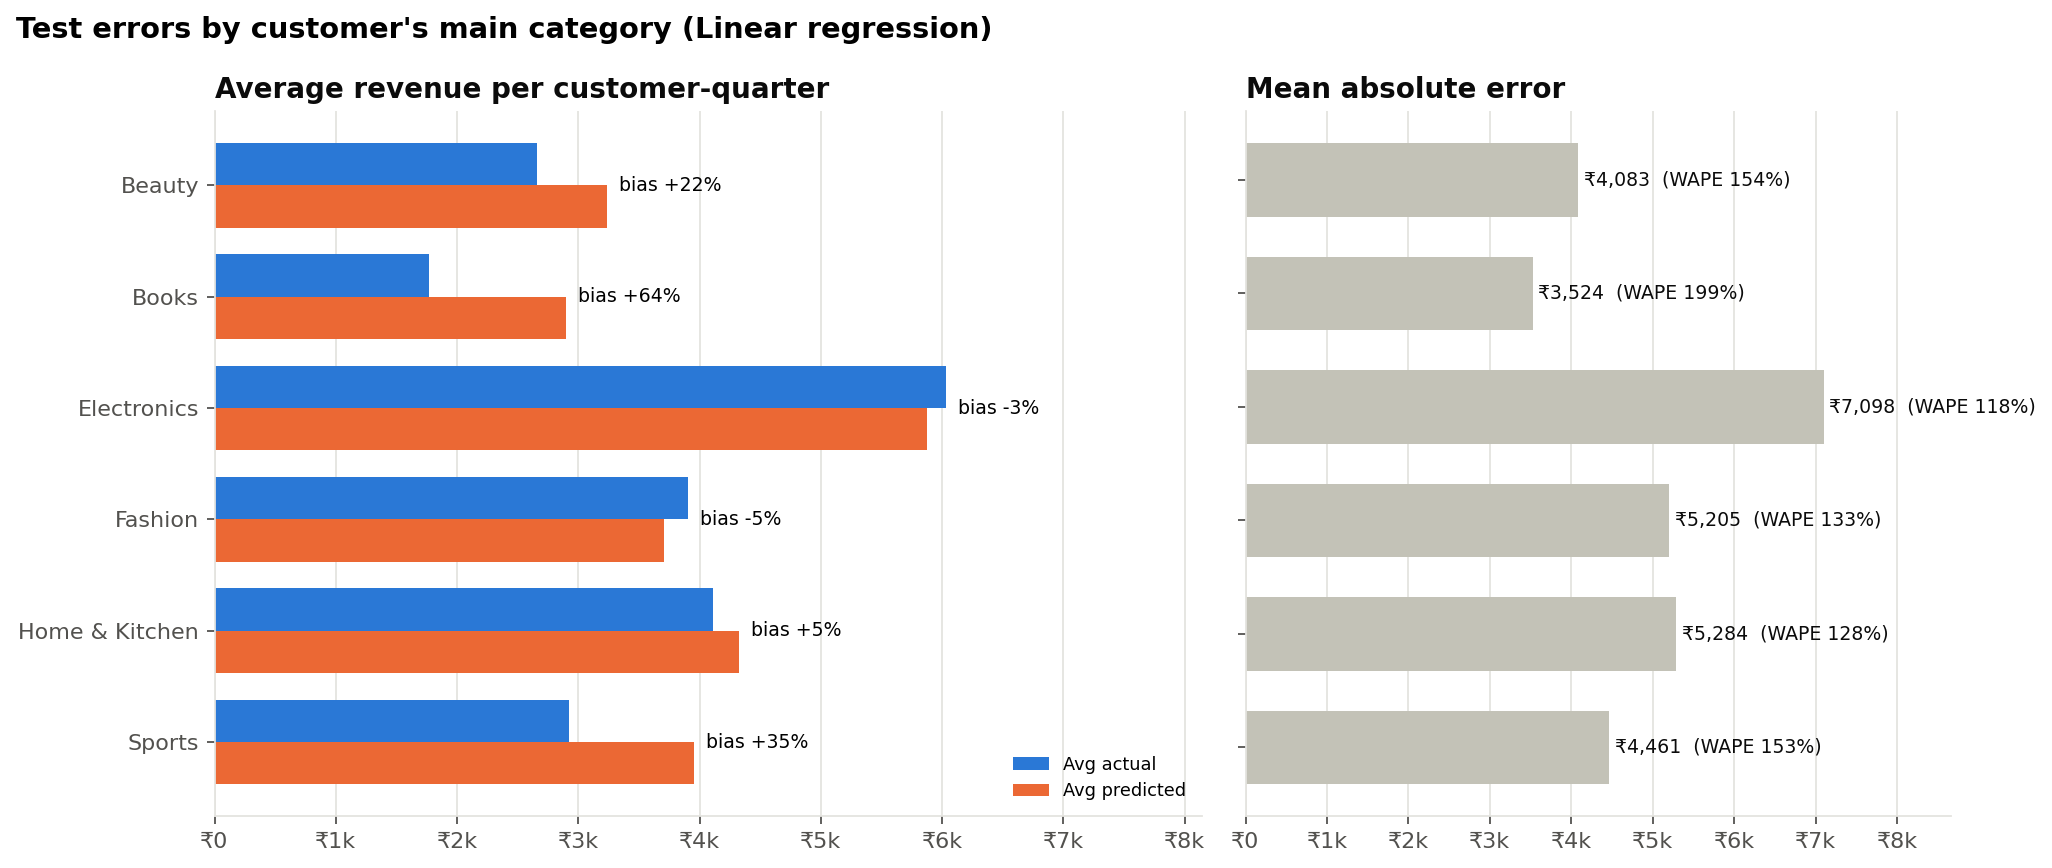

In [35]:
Image(str(FIG / "prediction_error_by_category.png"))

In [36]:
R['errors']['range']

,Revenue_Range,Rows,Actual_Revenue,Predicted_Revenue,MAE,Median_Abs_Error,WAPE_%,Bias_%,Avg_Actual,Avg_Predicted
0,Rs 0 (no purchase),1543,0.000,"6,497,760.924","4,241.577","4,211.656",NaN,NaN,0.000,"4,211.122"
1,Rs 1-5k,767,"1,689,392.700","3,076,280.265","2,582.152","2,198.250",117.232,82.094,"2,202.598","4,010.796"
2,Rs 5k-15k,378,"3,263,551.250","2,020,998.253","3,856.646","3,452.111",44.670,-38.074,"8,633.733","5,346.556"
3,Rs 15k-40k,167,"4,145,243.650","1,038,328.660","18,604.281","17,155.526",74.951,-74.951,"24,821.818","6,217.537"
4,Rs 40k+,58,"3,794,371.300","403,870.307","58,456.914","50,870.232",89.356,-89.356,"65,420.195","6,963.281"


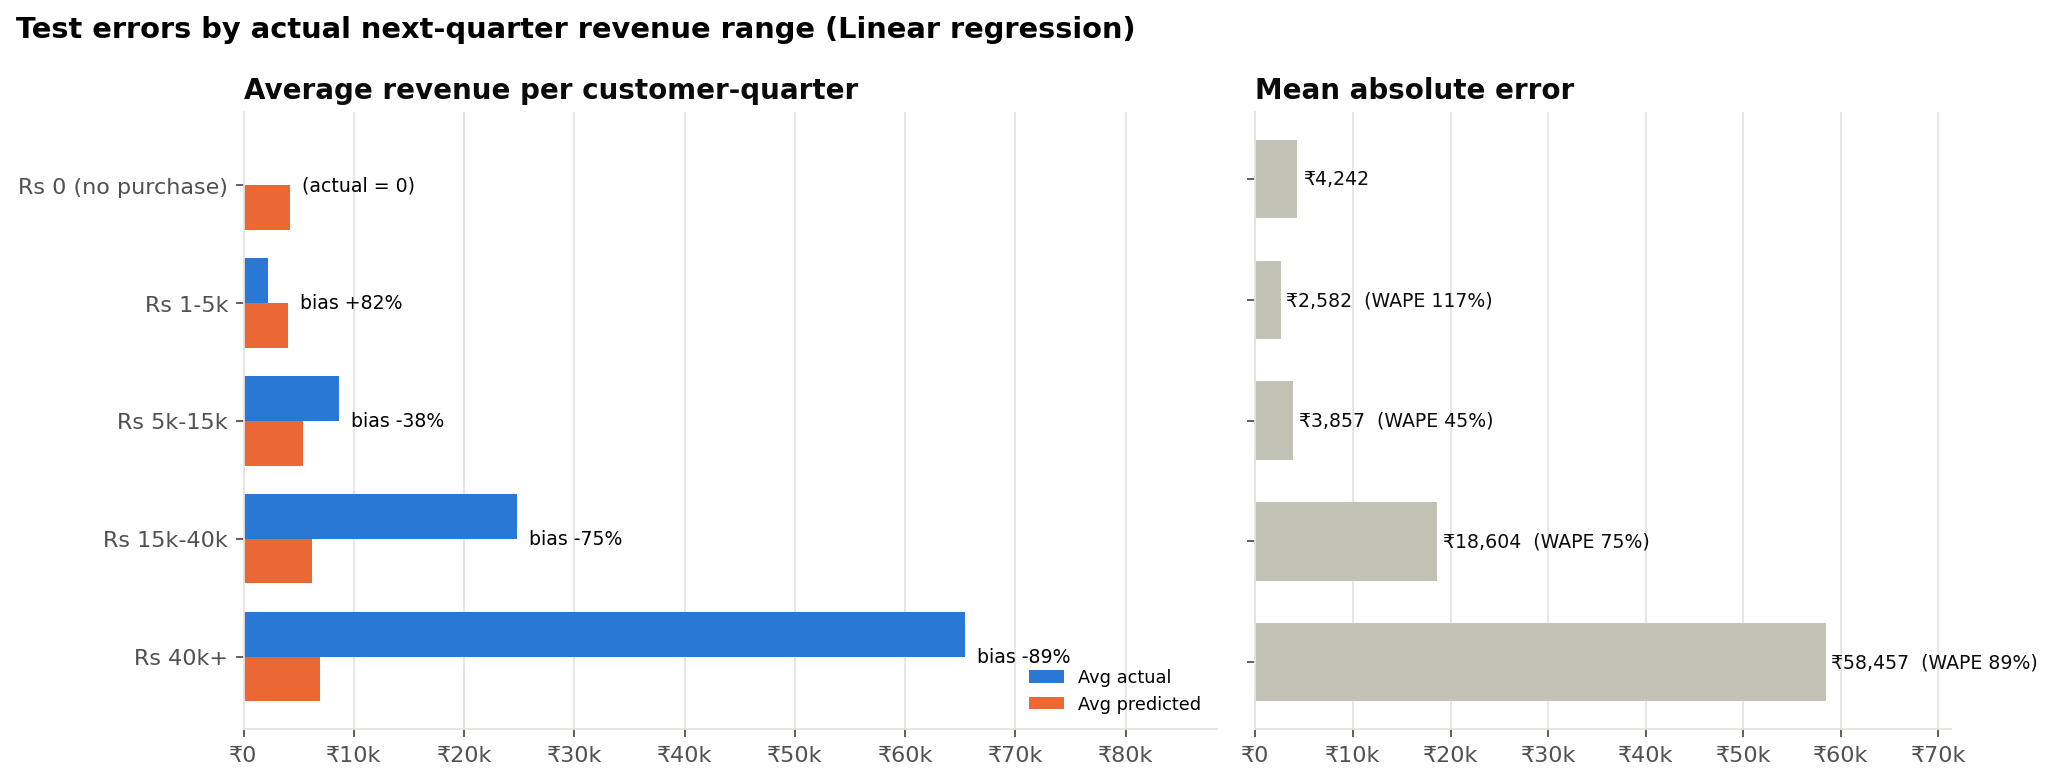

In [37]:
Image(str(FIG / "prediction_error_by_revenue_range.png"))

- **Pull toward the average:** the model over-predicts customers who buy nothing and under-predicts big spenders. Customers with ₹40k+ in the quarter were under-predicted by 89%.
- **Region:** errors are similar across regions.
- **Category:** small categories (Books, Sports) are over-predicted.
- **Segment and cluster:** the same pattern appears. The high-value segments are under-predicted and the lapsing segments are over-predicted.

## 15. Business Driver Analysis

In [38]:
R['drivers']['drivers']

,Driver,Group,Importance_Rank,Model_Evidence,Data_Evidence,Business_Interpretation,Limitation
0,Orders_12M,Customer history,1,Permutation: shuffling it raises test MAE by ₹236,"Spearman +0.26 with next-quarter revenue; mean revenue by feature quartile ₹2,003 (lowest) -> ₹7,079 (highest)",The model relied on this feature when predicting next-quarter revenue,Association with past behaviour; does not show that changing it would change revenue
1,Main_Category,Product,2,Permutation: shuffling it raises test MAE by ₹41,"Mean next-quarter revenue: highest Electronics ₹4,904, lowest Books ₹2,180",The model relied on this feature when predicting next-quarter revenue,Product mix is correlated with price level and customer type; not a causal effect
2,Share_Books,Product,3,Permutation: shuffling it raises test MAE by ₹41,"Spearman +0.04 with next-quarter revenue; mean revenue by feature quartile ₹3,018 (lowest) -> ₹4,542 (highest)",The model relied on this feature when predicting next-quarter revenue,Product mix is correlated with price level and customer type; not a causal effect
3,AOV_12M,Customer history,4,Permutation: shuffling it raises test MAE by ₹19,"Spearman +0.15 with next-quarter revenue; mean revenue by feature quartile ₹2,020 (lowest) -> ₹5,086 (highest)",The model relied on this feature when predicting next-quarter revenue,Association with past behaviour; does not show that changing it would change revenue
4,Categories_12M,Product,5,Permutation: shuffling it raises test MAE by ₹13,"Spearman +0.23 with next-quarter revenue; mean revenue by feature quartile ₹1,942 (lowest) -> ₹6,584 (highest)",The model relied on this feature when predicting next-quarter revenue,Product mix is correlated with price level and customer type; not a causal effect
5,Acquisition_Status,Customer history,6,Permutation: shuffling it raises test MAE by ₹9,"Mean next-quarter revenue: highest Existing before 2023 ₹4,092, lowest Acquired 2023-2025 ₹3,304",The model relied on this feature when predicting next-quarter revenue,Association with past behaviour; does not show that changing it would change revenue
6,Profit_Margin_12M,Customer history,7,Permutation: shuffling it raises test MAE by ₹6,"Spearman -0.08 with next-quarter revenue; mean revenue by feature quartile ₹4,344 (lowest) -> ₹2,585 (highest)",The model relied on this feature when predicting next-quarter revenue,Association with past behaviour; does not show that changing it would change revenue
7,Share_Home_Kitchen,Product,8,Permutation: shuffling it raises test MAE by ₹5,"Spearman +0.11 with next-quarter revenue; mean revenue by feature quartile ₹2,337 (lowest) -> ₹3,900 (highest)",The model relied on this feature when predicting next-quarter revenue,Product mix is correlated with price level and customer type; not a causal effect
8,Share_Sports,Product,9,Permutation: shuffling it raises test MAE by ₹5,"Spearman +0.10 with next-quarter revenue; mean revenue by feature quartile ₹2,829 (lowest) -> ₹4,993 (highest)",The model relied on this feature when predicting next-quarter revenue,Product mix is correlated with price level and customer type; not a causal effect
9,Avg_Discount_12M,Customer history,10,Permutation: shuffling it raises test MAE by ₹4,"Spearman -0.08 with next-quarter revenue; mean revenue by feature quartile ₹3,879 (lowest) -> ₹2,212 (highest)",The model relied on this feature when predicting next-quarter revenue,Association with past behaviour; does not show that changing it would change revenue


In [39]:
R['drivers']['categorical']

,Feature,Level,Rows,Mean_Next_Quarter_Revenue,Share_With_Purchase_%
0,Region,Central,948,"3,426.176",45.781
1,Region,East,950,"3,507.966",46.842
2,Region,North,1679,"4,132.617",46.397
3,Region,South,2020,"3,678.414",44.455
4,Region,West,1883,"3,530.011",45.459
5,Main_Category,Beauty,759,"2,650.171",39.921
6,Main_Category,Books,257,"2,179.638",39.300
7,Main_Category,Electronics,2297,"4,904.492",49.848
8,Main_Category,Fashion,2283,"3,120.386",43.408
9,Main_Category,Home & Kitchen,1517,"3,608.328",46.078


In [40]:
R['scenarios']

,Scenario,Change_Applied,Total_Predicted_Revenue,Change_vs_Current_%,Rows_Outside_Training_Range_%,Label
0,Current (actual test features),none,"13,037,238.408",0.000,0.000,"Model-based scenario (association, not a guaranteed outcome)"
1,Purchase frequency +10%,"orders (12m, 3m) and recent revenue history x 1.10 (AOV unchanged)","13,759,950.456",5.543,0.275,"Model-based scenario (association, not a guaranteed outcome)"
2,Average order value +10%,"AOV, unit price and recent revenue history x 1.10 (orders unchanged)","13,111,938.485",0.573,0.034,"Model-based scenario (association, not a guaranteed outcome)"
3,Average discount -2 percentage points,Avg_Discount_12M - 0.02 (floored at 0); nothing else,"13,208,639.970",1.315,0.000,"Model-based scenario (association, not a guaranteed outcome)"


**Model-based scenarios, not guaranteed outcomes.** Under the model's assumptions:
- purchase frequency +10% → about +5.5% predicted revenue;
- AOV +10% → about +0.6%;
- 2 percentage points less average discount → about +1.3%.

The discount result reflects that lower-discount customers historically spent more. It does **not** show that cutting discounts would raise revenue.

## 16. Business Interpretation

In [41]:
R['questions']

,Question,Answer
0,Can future revenue be predicted from historical/business features?,"Partly. On the unseen test quarters (2025-Q3, Q4) the final model explains R² 0.06 of the variation in customer-level next-quarter revenue, vs -0...."
1,Which variables are most useful for predicting revenue?,"By permutation importance on the test set: Orders_12M, Main_Category, Share_Books, AOV_12M, Categories_12M."
2,How accurately can revenue be predicted?,"MAE ₹5,658 per customer-quarter, RMSE ₹11,232, WAPE 127.8%, total bias +1.1% over the two test quarters combined. 53.0% of test customer-quarters ..."
3,"Which customer, product, pricing, discount and regional characteristics are associated with revenue?","Customer purchase history dominates (see driver table). Product, price and region features rank lower: Main_Category rank 2; Avg_Discount_12M rank..."
4,How can predicted revenue support business planning?,It gives an expected next-quarter revenue per existing customer that can rank customers and be summed by region or category (test bias by region -...


**How to use this:**
- **Use the customer-level estimates to rank and group customers** (e.g. expected revenue by region or category).
- **Treat single-customer estimates as rough indications,** not commitments.
- **Don't use the model alone to set a single-quarter revenue target:** its seasonality is weak, and the naive rule was closer for quarterly totals.
- **The strongest signal is purchase frequency,** which matches Steps 5–7.

## 17. Revenue Prediction Summary

In [42]:
R['validation']

,Area,Check,Value,Pass
0,Target,Target = Delivered Sales in the 3 months after each cutoff (recomputed independently),"10,393 rows",True
1,Target,"Target dates only inside [cutoff, cutoff + 3 months)",2024-01-01 .. 2025-12-31,True
2,Leakage,No feature uses data on/after its cutoff,max feature date < cutoff at all 8 cutoffs,True
3,Leakage,Preprocessor fitted on training rows only (validation step); final refit on train+validation only,"final fit rows 7,480 = train 4,788 + validation 2,692",True
4,Time,Training targets end before validation targets start; validation before test,2024-12-31 < 2025-01-01; 2025-06-30 < 2025-07-01,True
5,Time,Test split unused during selection/tuning,selection table uses Val_* columns only,True
6,Model,Feature selection (training rows) reproduces the model feature list; non-protected VIF <= 10,"19 numeric features, max VIF 10.0 (protected above 10: Avg_Unit_Price_12M 13.5)",True
7,Model,Baselines exist,3 baselines,True
8,Model,Multiple ML models evaluated,4 models,True
9,Model,Reported test metrics recomputed from the saved prediction table,R² 0.0557,True


In [43]:
fin = R["selection"]["chosen"]
t = R["test_results"].set_index("Model").loc[fin]
pipe = joblib.load(ROOT / "models" / "revenue_prediction_model.pkl")
same = np.allclose(pipe.predict(R["split"]["test"][pr.FEATURES]), R["preds"]["predictions"]["Predicted_Revenue"])
pd.DataFrame([
    ("Prediction unit", "customer x quarter (active in prior 12 months)"),
    ("Target", "Delivered revenue in the next 3 months"),
    ("Train / validation / test targets", "2024-Q1..Q4 / 2025-Q1..Q2 / 2025-Q3..Q4"),
    ("Final model", fin),
    ("Test MAE / RMSE / R²", f"Rs {t['MAE']:,.0f} / Rs {t['RMSE']:,.0f} / {t['R2']:.3f}"),
    ("Test total bias (two quarters)", f"{t['Total_Bias_%']:+.1f}%"),
    ("Top features (permutation)", ", ".join(R["importance"].head(5)["Feature"])),
    ("Saved pipeline reproduces test predictions", str(same)),
    ("Validation checks passed", f"{int(R['validation']['Pass'].sum())}/{len(R['validation'])}"),
], columns=["Item", "Result"])

,Item,Result
0,Prediction unit,customer x quarter (active in prior 12 months)
1,Target,Delivered revenue in the next 3 months
2,Train / validation / test targets,2024-Q1..Q4 / 2025-Q1..Q2 / 2025-Q3..Q4
3,Final model,Linear regression
4,Test MAE / RMSE / R²,"Rs 5,658 / Rs 11,232 / 0.056"
5,Test total bias (two quarters),+1.1%
6,Top features (permutation),"Orders_12M, Main_Category, Share_Books, AOV_12M, Categories_12M"
7,Saved pipeline reproduces test predictions,True
8,Validation checks passed,17/17
